# Heart Disease UCI — model training, tuning and experiment tracking

This notebook runs the training pipeline in `src/heart/train.py` and inspects its results. The logic lives in the package, so the notebook, the command line (`python -m heart.train`), the CI workflow and the Docker build all train the same way.

For each candidate model the pipeline:

1. tunes hyperparameters with a grid search over **stratified 5-fold cross-validation** on the training split (refit on F2);
2. reports accuracy, precision, recall, F1, F2 and ROC-AUC as cross-validated mean ± std, and again on the training and held-out test splits;
3. logs one **MLflow run** with parameters, metrics, tags (git commit, data checksums), plots, tables, the environment files and the model, plus one child run per grid combination with its parameters and cross-validated scores.

The model with the highest cross-validated **F2** score is selected. F2 weights recall twice as much as precision, because a missed disease case (false negative) is the costly error. Selection uses cross-validation only, so the test split stays an unbiased final check. The selected model is saved to `models/model.joblib` and registered in the MLflow Model Registry with the alias `champion`.

Prerequisite: `python scripts/download_data.py` has written `data/processed/heart_clean.csv`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import Image, display

from heart import train
from heart.config import MODEL_PATH, REPORTS_DIR
from heart.models import CANDIDATES

%matplotlib inline
# heart.train selects the non-interactive Agg backend for scripts; plots are shown inline here.

METRICS = list(train.SCORERS)
for name, spec in CANDIDATES.items():
    grid = spec["grid"]
    print(
        f"{name}: {type(spec['estimator']).__name__}, grid "
        + " x ".join(f"{k.replace('model__', '')}={len(v)}" for k, v in grid.items())
    )

logistic_regression: LogisticRegression, grid C=4 x l1_ratio=2 x class_weight=2
random_forest: RandomForestClassifier, grid n_estimators=2 x max_depth=3 x min_samples_leaf=2 x class_weight=2


## Train, tune and track every candidate

In [2]:
train.main()

Registered model 'heart-disease-classifier' already exists. Creating a new version of this model...
Created version '2' of model 'heart-disease-classifier'.


Cross-validation (training split, mean ± std over 5 folds):
              model      accuracy     precision        recall            f1            f2       roc_auc
logistic_regression 0.855 ± 0.030 0.861 ± 0.075 0.828 ± 0.054 0.840 ± 0.030 0.832 ± 0.038 0.907 ± 0.019
      random_forest 0.826 ± 0.037 0.830 ± 0.059 0.792 ± 0.095 0.805 ± 0.046 0.796 ± 0.074 0.895 ± 0.027

Held-out test split:
              model  accuracy  precision  recall    f1    f2  roc_auc
logistic_regression     0.885      0.818   0.964 0.885 0.931    0.959
      random_forest     0.885      0.862   0.893 0.877 0.887    0.945

Selected: logistic_regression -> models/model.joblib, registered as heart-disease-classifier v2 (alias 'champion')


## Cross-validated metrics (training split)

Mean and standard deviation over the 5 folds, for the best hyperparameters of each model.

In [3]:
summary = json.loads((REPORTS_DIR / "metrics.json").read_text())
results = {r["name"]: r for r in summary["models"]}
cv = pd.DataFrame(
    {
        name: {m: f"{r[f'cv_{m}_mean']:.3f} ± {r[f'cv_{m}_std']:.3f}" for m in METRICS}
        for name, r in results.items()
    }
).T
display(cv)
print(f"Split: {summary['split']['train']} training rows, {summary['split']['test']} test rows.")
print("Best hyperparameters:")
for name, r in results.items():
    print(f"  {name}: {r['best_params']} (grid of {r['grid_size']} combinations)")

,accuracy,precision,recall,f1,f2,roc_auc
logistic_regression,0.855 ± 0.030,0.861 ± 0.075,0.828 ± 0.054,0.840 ± 0.030,0.832 ± 0.038,0.907 ± 0.019
random_forest,0.826 ± 0.037,0.830 ± 0.059,0.792 ± 0.095,0.805 ± 0.046,0.796 ± 0.074,0.895 ± 0.027


Split: 242 training rows, 61 test rows.
Best hyperparameters:
  logistic_regression: {'C': 1.0, 'class_weight': 'balanced', 'l1_ratio': 0.0} (grid of 16 combinations)
  random_forest: {'class_weight': None, 'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 400} (grid of 24 combinations)


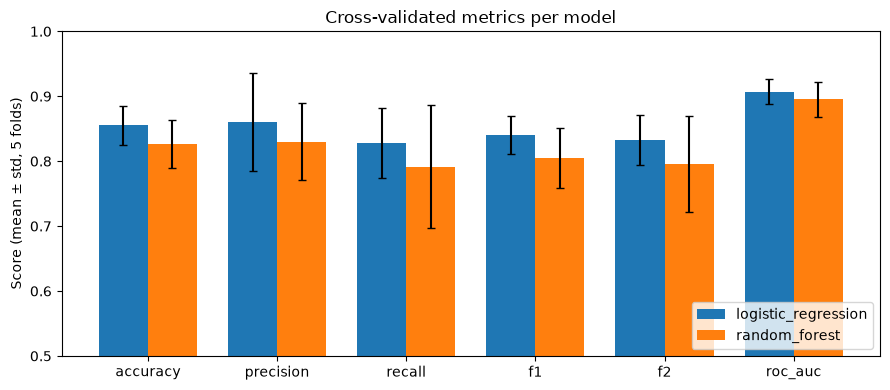

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.38
for k, (name, r) in enumerate(results.items()):
    x = [i + (k - 0.5) * width for i in range(len(METRICS))]
    ax.bar(
        x,
        [r[f"cv_{m}_mean"] for m in METRICS],
        width,
        yerr=[r[f"cv_{m}_std"] for m in METRICS],
        capsize=3,
        label=name,
    )
ax.set_xticks(range(len(METRICS)), METRICS)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Score (mean ± std, 5 folds)")
ax.set_title("Cross-validated metrics per model")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "figures" / "cv_metrics.png", dpi=150)
plt.show()

## Held-out test split and overfitting check

A large gap between the training and test scores would mean the model memorised the training rows.

In [5]:
rows = []
for name, r in results.items():
    for split in ["train", "test"]:
        rows.append(
            {"model": name, "split": split, **{m: round(r[f"{split}_{m}"], 3) for m in METRICS}}
        )
table = pd.DataFrame(rows).set_index(["model", "split"])
display(table)
for name, r in results.items():
    gap = r["train_roc_auc"] - r["test_roc_auc"]
    print(
        f"{name}: ROC-AUC train {r['train_roc_auc']:.3f} vs test {r['test_roc_auc']:.3f} "
        f"(gap {gap:+.3f}); test recall {r['test_recall']:.3f}."
    )

accuracy  precision  recall     f1     f2  roc_auc
model               split                                                    
logistic_regression train     0.860      0.867   0.820  0.843  0.829    0.929
                    test      0.885      0.818   0.964  0.885  0.931    0.959
random_forest       train     0.860      0.881   0.802  0.840  0.817    0.939
                    test      0.885      0.862   0.893  0.877  0.887    0.945

logistic_regression: ROC-AUC train 0.929 vs test 0.959 (gap -0.030); test recall 0.964.
random_forest: ROC-AUC train 0.939 vs test 0.945 (gap -0.006); test recall 0.893.


## Hyperparameter search

Cross-validated F2 for every combination in each grid (full tables: `reports/runs/<model>/cv_results.csv`, also logged to MLflow).

In [6]:
for name in results:
    grid = pd.read_csv(REPORTS_DIR / "runs" / name / "cv_results.csv")
    params = [c for c in grid.columns if c.startswith("param_")]
    view = grid[params + ["mean_test_f2", "std_test_f2", "mean_test_roc_auc"]]
    view = view.rename(columns=lambda c: c.replace("param_model__", ""))
    view = view.sort_values("mean_test_f2", ascending=False).round(3)
    print(f"{name}: top 5 of {len(view)} combinations by CV F2")
    display(view.head(5).reset_index(drop=True))

logistic_regression: top 5 of 16 combinations by CV F2


,C,class_weight,l1_ratio,mean_test_f2,std_test_f2,mean_test_roc_auc
0,1.00,balanced,0.0,0.832,0.038,0.907
1,10.00,NaN,0.0,0.815,0.014,0.904
2,10.00,NaN,1.0,0.815,0.014,0.904
3,1.00,balanced,1.0,0.814,0.050,0.900
4,0.01,balanced,0.0,0.813,0.074,0.893


random_forest: top 5 of 24 combinations by CV F2


,class_weight,max_depth,min_samples_leaf,n_estimators,mean_test_f2,std_test_f2,mean_test_roc_auc
0,NaN,3.0,1,400,0.796,0.074,0.895
1,balanced,5.0,1,200,0.790,0.074,0.895
2,NaN,3.0,5,400,0.790,0.072,0.896
3,NaN,3.0,5,200,0.790,0.072,0.898
4,balanced,5.0,5,400,0.789,0.060,0.898


## Plots of the selected and the other candidate (test split)

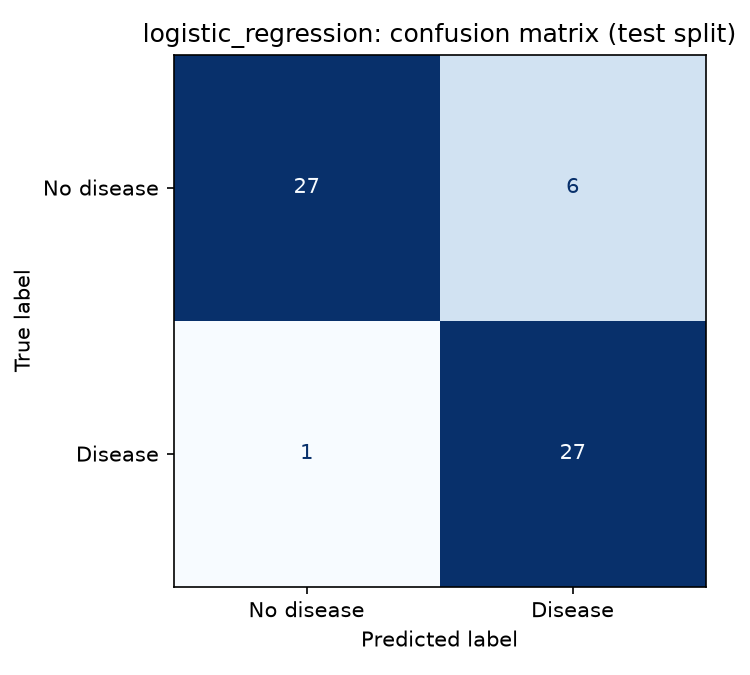

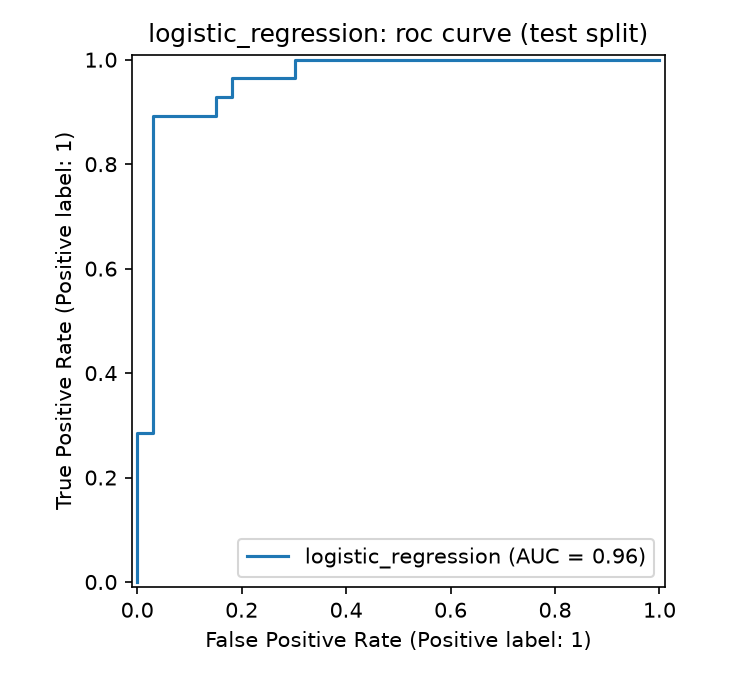

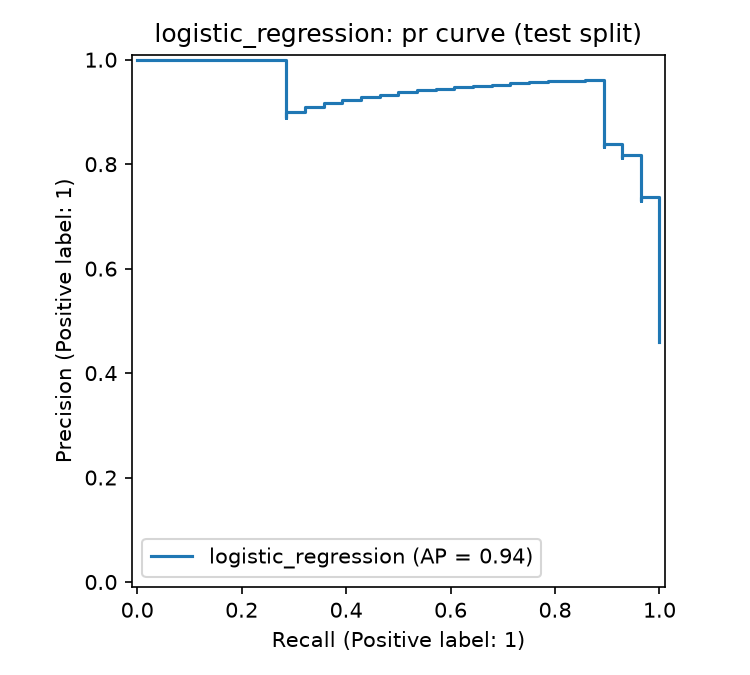

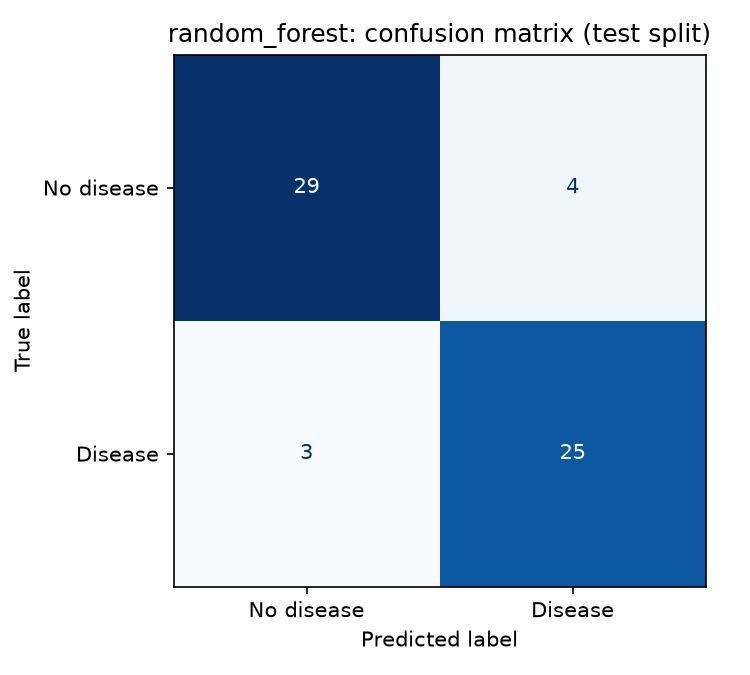

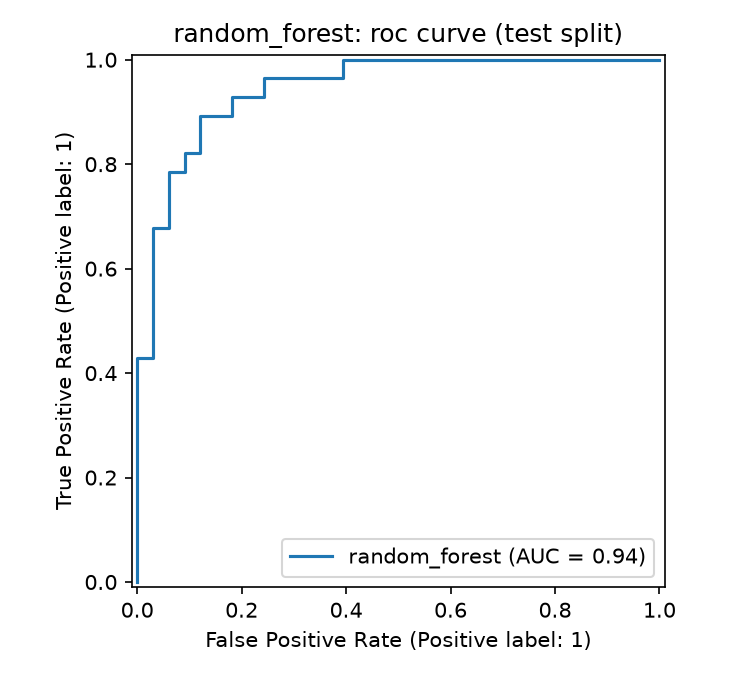

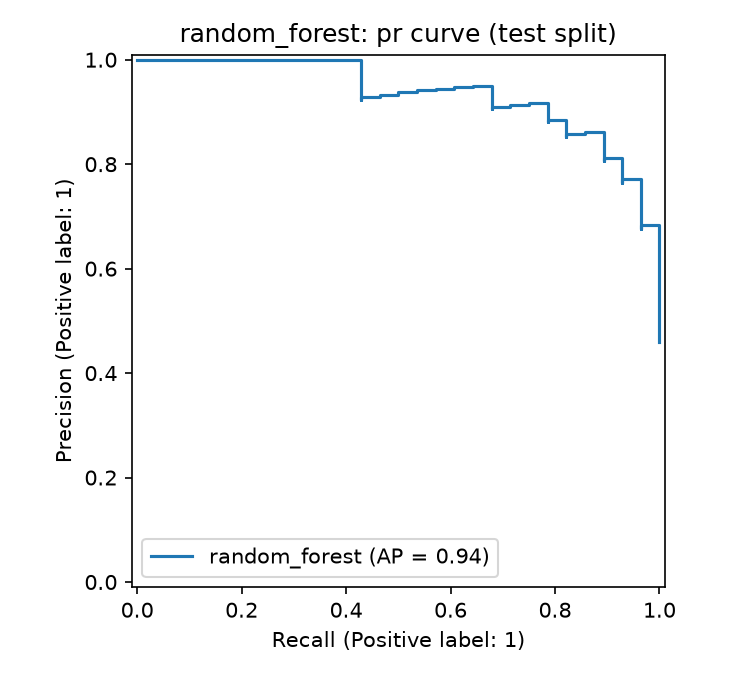

In [7]:
for name in results:
    for kind in ["confusion_matrix", "roc_curve", "pr_curve"]:
        display(Image(filename=str(REPORTS_DIR / "runs" / name / f"{name}_{kind}.png"), width=360))

## What the selected model relies on

Coefficients for logistic regression (on standardised and one-hot columns), impurity importances for the random forest.

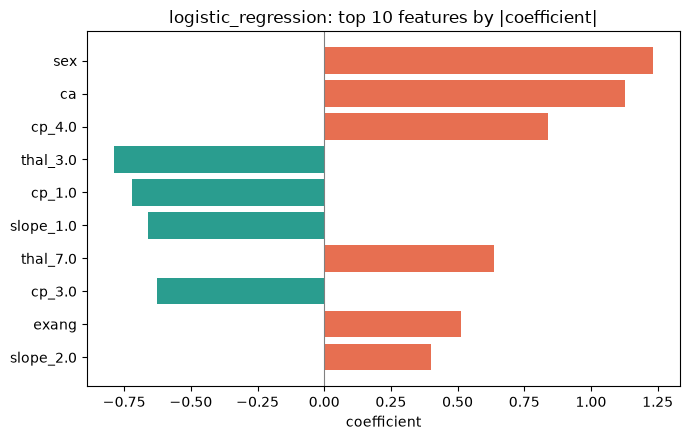

Largest effects: sex (+1.23), ca (+1.13), cp_4.0 (+0.84), thal_3.0 (-0.79).


In [8]:
selected = summary["selected_model"]
imp = pd.read_csv(REPORTS_DIR / "runs" / selected / "feature_importance.csv")
value = imp.columns[1]
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top["feature"], top[value], color=["#e76f51" if v > 0 else "#2a9d8f" for v in top[value]])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel(value)
ax.set_title(f"{selected}: top 10 features by |{value}|")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "figures" / "feature_importance.png", dpi=150)
plt.show()
print(
    "Largest effects: "
    + ", ".join(f"{f} ({v:+.2f})" for f, v in imp.head(4)[["feature", value]].values)
    + "."
)

## Model selection and registry

In [9]:
winner = results[selected]
others = [n for n in results if n != selected]
print(f"Selected: {selected} by {summary['selection_rule']}.")
for n in others:
    print(
        f"  CV F2 {winner['cv_f2_mean']:.3f} ({selected}) vs {results[n]['cv_f2_mean']:.3f} ({n})."
    )
print(f"Saved to: {MODEL_PATH.relative_to(ROOT)}")

client = mlflow.MlflowClient()
reg = summary["registered_model"]
champion = client.get_model_version_by_alias(reg["name"], "champion")
print(
    f"Registry: {reg['name']} version {champion.version} has alias 'champion' "
    f"(run {champion.run_id[:8]}, tags {champion.tags})."
)

runs = mlflow.search_runs(experiment_names=[train.EXPERIMENT])
children = runs["tags.mlflow.parentRunId"].notna()
print(f"{(~children).sum()} model runs and {children.sum()} grid-combination child runs.")
runs = runs[~children]
cols = [
    "tags.mlflow.runName",
    "start_time",
    "metrics.cv_f2_mean",
    "metrics.test_roc_auc",
    "tags.git_commit",
    "tags.data_md5_clean",
]
display(runs[cols].head(6))
print("Browse every run with: mlflow ui --backend-store-uri sqlite:///mlflow.db")

Selected: logistic_regression by highest cv_f2_mean (tie-break cv_roc_auc_mean).
  CV F2 0.832 (logistic_regression) vs 0.796 (random_forest).
Saved to: models/model.joblib
Registry: heart-disease-classifier version 2 has alias 'champion' (run 095a8df9, tags {'selected_by': 'cv_f2_mean'}).
4 model runs and 80 grid-combination child runs.


,tags.mlflow.runName,start_time,metrics.cv_f2_mean,metrics.test_roc_auc,tags.git_commit,tags.data_md5_clean
24,random_forest,2026-10-19 19:28:40.915000+00:00,0.795665,0.944805,unversioned,a2118cf75741522d145d36aa714dc8fa
41,logistic_regression,2026-10-19 19:28:14.300000+00:00,0.832168,0.958874,unversioned,a2118cf75741522d145d36aa714dc8fa
66,random_forest,2026-10-19 19:27:37.033000+00:00,0.795665,0.944805,unversioned,a2118cf75741522d145d36aa714dc8fa
83,logistic_regression,2026-10-19 19:27:11.748000+00:00,0.832168,0.958874,unversioned,a2118cf75741522d145d36aa714dc8fa


Browse every run with: mlflow ui --backend-store-uri sqlite:///mlflow.db
